In [8]:
import pandas as pd                      # tables (DataFrame): load and clean data
import numpy as np                       # fast maths on arrays
import matplotlib.pyplot as plt          # basic plotting
import seaborn as sns                    # prettier plots (we use it for heatmaps)
 
from sklearn.model_selection import train_test_split, cross_val_score
# train_test_split : cuts data into train and test parts
# cross_val_score  : tests a model several times on different slices of the TRAIN data
#                    (used to choose settings like K without touching the test set)
 
from sklearn.preprocessing import MinMaxScaler
# MinMaxScaler : rescales every column to the range 0..1
 
from sklearn.neighbors import KNeighborsClassifier   # model 1: KNN
from sklearn.svm import SVC                          # model 2: SVM (SVC = Support Vector Classifier)
 
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

In [9]:
# %% STEP 1: LOAD THE DATA
df = pd.read_csv('emails.csv')           # read the CSV file into a DataFrame
print(df.shape)                          # (rows, columns)  -> columns = ~3000 words + id + label
print(df.head())                         # first 5 rows
print(df['Prediction'].value_counts())
# .value_counts() = how many emails of each class. 0 = Not Spam, 1 = Spam.
# WHY: we must know if classes are balanced. If 90% were not-spam, a lazy model
# that always says "not spam" would show 90% accuracy and still be useless.

(5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
Prediction
0    3672
1    1500
Name: count, dtype

In [10]:
# %% STEP 2: PRE-PROCESSING
print(df.isnull().sum().sum())
# df.isnull() marks empty cells; the first .sum() counts per column, the second
# adds them all up -> total number of missing values in the whole table.
 
df = df.dropna()
# .dropna() = delete rows containing a missing value (the model cannot use blanks).
 
df = df.drop(columns=['Email No.'])
# 'Email No.' is only an id like "Email 17" (text). It tells nothing about spam,
# and models need numbers, so we remove it.
 
X = df.drop(columns=['Prediction'])      # X = inputs  : the word counts
y = df['Prediction']                     # y = answer  : 0 = Not Spam, 1 = Spam
print("Features:", X.shape[1], "| Emails:", X.shape[0])



0
Features: 3000 | Emails: 5172


In [11]:
# %% STEP 3: TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

In [12]:
# %% STEP 4: FEATURE SCALING
scaler = MinMaxScaler()                        # create the scaler
X_train = scaler.fit_transform(X_train)        # fit() learns each column's min and max from TRAIN,
                                               # transform() converts values to 0..1. Done together here.
X_test  = scaler.transform(X_test)             # apply the SAME min/max to test (never fit on test)

K= 1  cross-val accuracy = 0.9243
K= 3  cross-val accuracy = 0.9202
K= 5  cross-val accuracy = 0.9215
K= 7  cross-val accuracy = 0.9257
K= 9  cross-val accuracy = 0.9296
K=11  cross-val accuracy = 0.9320
Best K: 11


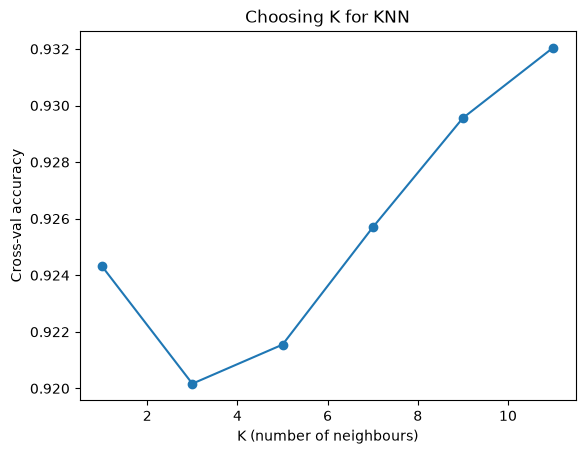

In [13]:
 #%% STEP 5: CHOOSE K FOR KNN (using only the training data)
# K = how many neighbours vote. K too small -> noisy; K too large -> too blurry.
# Instead of guessing (the teacher used 7), we test a few values.
k_values = [1, 3, 5, 7, 9, 11]
cv_scores = []
for k in k_values:
    knn_try = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    # metric='cosine' : measures the ANGLE between two emails' word-count vectors
    # instead of straight-line distance. For text, this works better because it
    # compares the "mix of words" rather than the email's length.
    score = cross_val_score(knn_try, X_train, y_train, cv=5).mean()
    # cross_val_score(model, X, y, cv=5): splits train data into 5 parts, trains on 4,
    # tests on 1, repeats 5 times, returns 5 accuracy scores. .mean() averages them.
    cv_scores.append(score)
    print(f"K={k:2d}  cross-val accuracy = {score:.4f}")
 
best_k = k_values[int(np.argmax(cv_scores))]
# np.argmax = position of the biggest value; we use it to pick the best K.
print("Best K:", best_k)
 
plt.plot(k_values, cv_scores, marker='o')
plt.xlabel('K (number of neighbours)'); plt.ylabel('Cross-val accuracy')
plt.title('Choosing K for KNN'); plt.show()

In [14]:
#  %% STEP 6: TRAIN AND PREDICT - KNN
knn = KNeighborsClassifier(n_neighbors=best_k, metric='cosine')
knn.fit(X_train, y_train)       # KNN "training" just stores the emails (it is a lazy learner)
knn_pred = knn.predict(X_test)  # for each test email: find K nearest train emails, majority vote
 

In [15]:
# %% STEP 7: TRAIN AND PREDICT - SVM
# SVC has two key settings:
#   C      : penalty for mistakes. High C = strict (may overfit); low C = tolerant.
#   kernel : shape of the boundary. 'linear' = straight line/plane; 'rbf' = curved.
# We compare both kernels with cross-validation (again using only train data).
best_score, best_kernel = 0, None
for kernel in ['linear', 'rbf']:
    s = cross_val_score(SVC(kernel=kernel, C=1), X_train, y_train, cv=5).mean()
    print(f"SVM kernel={kernel:6s}  cross-val accuracy = {s:.4f}")
    if s > best_score:
        best_score, best_kernel = s, kernel
print("Best kernel:", best_kernel)
 
svm = SVC(kernel=best_kernel, C=1)
svm.fit(X_train, y_train)        # finds the boundary (support vectors = the emails closest to it)
svm_pred = svm.predict(X_test)

SVM kernel=linear  cross-val accuracy = 0.9677
SVM kernel=rbf     cross-val accuracy = 0.9293
Best kernel: linear


       Model  Accuracy  Precision  Recall  F1-score
  KNN (K=11)    0.9330     0.9042  0.8600    0.8815
SVM (linear)    0.9678     0.9292  0.9622    0.9454

----- KNN -----
              precision    recall  f1-score   support

    Not Spam       0.94      0.96      0.95      1102
        Spam       0.90      0.86      0.88       450

    accuracy                           0.93      1552
   macro avg       0.92      0.91      0.92      1552
weighted avg       0.93      0.93      0.93      1552


----- SVM -----
              precision    recall  f1-score   support

    Not Spam       0.98      0.97      0.98      1102
        Spam       0.93      0.96      0.95       450

    accuracy                           0.97      1552
   macro avg       0.96      0.97      0.96      1552
weighted avg       0.97      0.97      0.97      1552



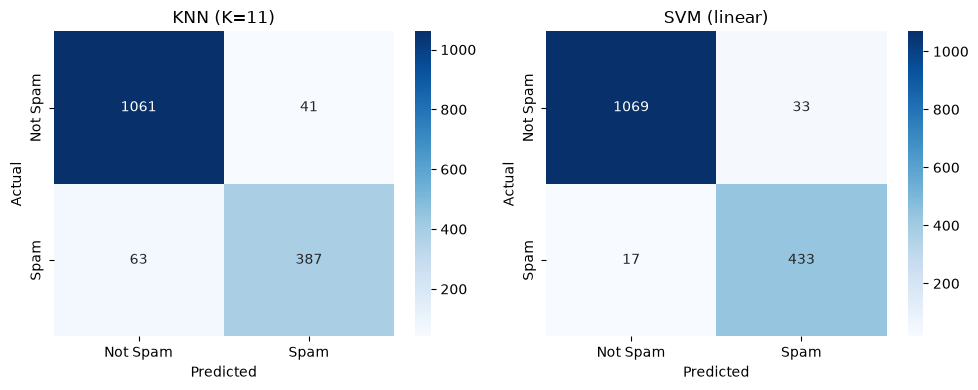

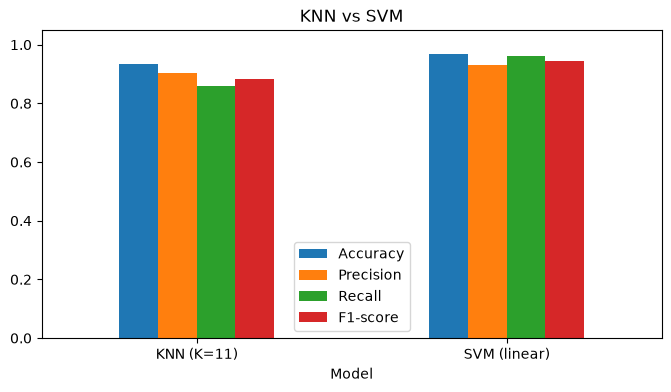

In [16]:
# %% STEP 8: ANALYSE PERFORMANCE
# Remember: 1 = Spam (positive class), 0 = Not Spam.
# CONFUSION MATRIX layout:        predicted 0 | predicted 1
#                       actual 0 :     TN     |     FP
#                       actual 1 :     FN     |     TP
#   TN = normal mail correctly kept          FP = normal mail wrongly marked spam (BAD: lost mail)
#   TP = spam correctly caught               FN = spam that slipped into the inbox
# METRICS:
#   Accuracy  = correct predictions / all predictions
#   Precision = of the emails we called spam, how many really were spam  = TP/(TP+FP)
#   Recall    = of all real spam, how much we caught                     = TP/(TP+FN)
#   F1-score  = balance of precision and recall (one number; high only if both are high)
 
def evaluate(name, pred):
    return {'Model': name,
            'Accuracy':  accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),   # for class 1 (spam) by default
            'Recall':    recall_score(y_test, pred),
            'F1-score':  f1_score(y_test, pred)}
 
results = pd.DataFrame([evaluate(f'KNN (K={best_k})', knn_pred),
                        evaluate(f'SVM ({best_kernel})', svm_pred)])
print(results.round(4).to_string(index=False))
 
for name, pred in [('KNN', knn_pred), ('SVM', svm_pred)]:
    print(f"\n----- {name} -----")
    print(classification_report(y_test, pred, target_names=['Not Spam', 'Spam']))
    # classification_report prints precision/recall/F1 for BOTH classes in one table.
 
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(axes, [knn_pred, svm_pred], [f'KNN (K={best_k})', f'SVM ({best_kernel})']):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
    # annot=True writes the counts inside cells, fmt='d' = whole numbers
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title)
plt.tight_layout(); plt.show()
 
# Bar chart comparing the metrics
results.set_index('Model').plot(kind='bar', ylim=(0, 1.05), rot=0, figsize=(8, 4),
                                title='KNN vs SVM')
plt.show()